# Phase 3 · Model 2 — Late-order risk

**Goal:** when an order is assigned, predict whether it will be delivered **late** (after its
deadline), so operators can act early.

**Data:** `data/processed/classical_ml/tasks.parquet` — the same file as the ETA model, different target.

Workflow: 1 Understand → 2 Explore → 3 Target + features → 4 Split → 5 Preprocess → 6 Baseline →
7 Train → 8 Validate & tune → 9 Test once → 10 Save & report.

## Step 1 — Understand the problem

| Question | Answer |
|---|---|
| What do we predict? | `late`: True if delivered after the deadline |
| When? | At assignment |
| Problem type | **Binary classification** |
| How do we judge it? | **Recall** (share of late orders we catch), **precision**, **F1**, **ROC-AUC** |

Accuracy is misleading here: if only ~12 % of orders are late, a model that always says "on time" is
88 % accurate and completely useless.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project root (the folder that contains data/processed), wherever the notebook runs.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed" / "classical_ml"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60)
print("Data folder:", DATA)

Data folder: H:\ai-warehouse-platform\data\processed\classical_ml


## Step 2 — Explore the data

Load the table and check how balanced the target is.

In [2]:
df = pd.read_parquet(DATA / "tasks.parquet")
print("Rows:", len(df))
print(df["late"].value_counts(normalize=True).rename("share").round(3))

Rows: 161221
late
False    0.878
True     0.122
Name: share, dtype: float64


Late share by priority and by hour: HIGH orders have the tightest deadline (240 ticks), and rush hours queue.

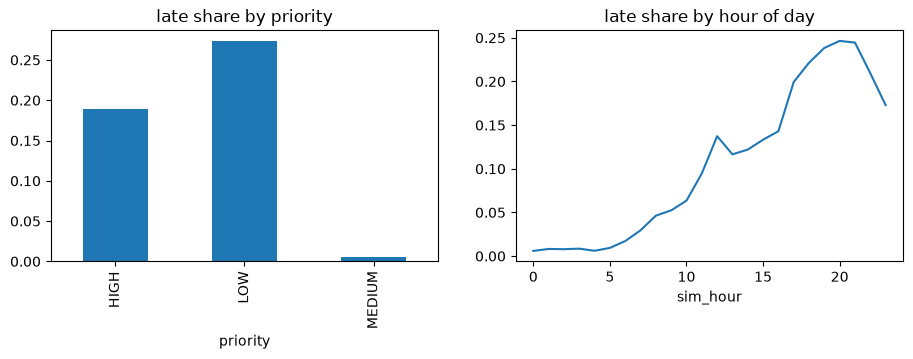

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
df.groupby("priority")["late"].mean().plot.bar(ax=ax[0], title="late share by priority")
df.groupby("sim_hour")["late"].mean().plot(ax=ax[1], title="late share by hour of day")
plt.show()

Late share against waiting time in the queue (known at assignment) — a strong signal.

In [4]:
bins = pd.cut(df["queue_ticks"], [-1, 0, 30, 60, 120, 240, 10_000])
df.groupby(bins, observed=True)["late"].agg(["mean", "size"]).round(3)

,mean,size
queue_ticks,,
"(-1, 0]",0.025,89965
"(0, 30]",0.094,41386
"(30, 60]",0.015,7181
"(60, 120]",0.017,3573
"(120, 240]",0.066,1923
"(240, 10000]",0.764,17193


## Step 3 — Choose the target and the features

- **Target:** `late`
- **Features:** the same "known at assignment" features as the ETA model.
- **Excluded:** `duration_ticks` (it *is* the answer), `delivered_at`, `moves`, `waits`, `reroutes`, IDs.

In [5]:
df["hour_sin"] = np.sin(2 * np.pi * df["sim_hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["sim_hour"] / 24)
for col in ["is_weekend", "is_promo_day"]:
    df[col] = df[col].astype(int)

NUMERIC = [
    "path_distance", "est_distance", "battery_start", "temperature_start", "robot_speed",
    "zone_congestion", "fleet_busy", "pending_orders", "queue_ticks", "closures_active",
    "floor_hazards_active", "n_items", "n_units", "total_weight_kg", "hour_sin", "hour_cos",
    "day_of_week", "is_weekend", "is_promo_day",
]  # fmt: skip
CATEGORICAL = ["priority", "main_category"]
LEAKS = ["moves", "waits", "reroutes", "delivered_at", "duration_ticks", "late"]
assert not set(LEAKS) & set(NUMERIC + CATEGORICAL), "a leak column is in the features!"
for col in CATEGORICAL:
    df[col] = df[col].astype(str)
TARGET = "late"
df[TARGET] = df[TARGET].astype(int)

## Step 4 — Split

The date-based `split` column: train on the first 9 weeks, tune on the next 2, test on the last 2.

In [6]:
train, val, test = (df[df["split"] == s] for s in ("train", "validation", "test"))
X_train, y_train = train[NUMERIC + CATEGORICAL], train[TARGET]
X_val, y_val = val[NUMERIC + CATEGORICAL], val[TARGET]
X_test, y_test = test[NUMERIC + CATEGORICAL], test[TARGET]
for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:10s} {len(y):7,} rows, late share {y.mean():.3f}")

train      106,273 rows, late share 0.079
validation  27,266 rows, late share 0.195
test        27,682 rows, late share 0.214


## Step 5 — Preprocess

Scale numbers, one-hot encode categories; fitted on train only inside each pipeline.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## Step 6 — Baseline

"Always on time": high accuracy, zero recall — this shows why accuracy is the wrong metric.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score


def scores(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba) if proba.std() > 0 else 0.5,
    }


dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results = {"Baseline (always on time)": scores(y_val, dummy.predict_proba(X_val)[:, 1])}
pd.DataFrame(results).T.round(3)

,accuracy,precision,recall,F1,ROC-AUC
Baseline (always on time),0.805,0.0,0.0,0.0,0.5


## Step 7 — Train models

Logistic Regression, Random Forest, Gradient Boosting and XGBoost, all **weighted** so the rare
"late" class counts as much as the common one (XGBoost: `scale_pos_weight` = on-time / late).

In [9]:
import time

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
candidates = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, min_samples_leaf=5, class_weight="balanced_subsample",
        n_jobs=-1, random_state=42,
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=ratio, tree_method="hist", n_jobs=-1, random_state=42,
    ),
}  # fmt: skip
fitted = {}
for name, model in candidates.items():
    start = time.time()
    fitted[name] = Pipeline([("prep", preprocess), ("model", model)]).fit(X_train, y_train)
    results[name] = scores(y_val, fitted[name].predict_proba(X_val)[:, 1])
    print(f"{name:20s} {time.time() - start:5.1f} s")
pd.DataFrame(results).T.round(3)

Logistic Regression    0.8 s


Random Forest         12.9 s


Gradient Boosting      7.2 s


XGBoost                7.8 s


,accuracy,precision,recall,F1,ROC-AUC
Baseline (always on time),0.805,0.000,0.000,0.000,0.500
Logistic Regression,0.899,0.664,0.977,0.791,0.988
Random Forest,0.942,0.815,0.910,0.860,0.985
Gradient Boosting,0.912,0.699,0.967,0.811,0.987
XGBoost,0.924,0.737,0.952,0.831,0.986


## Step 8 — Validate & tune

Choose the best model by validation **ROC-AUC** (how well it ranks late above on-time orders), then
tune the **decision threshold**: the probability above which we call an order "late". We scan
0.05–0.95 on validation and keep the threshold with the best F1 (balance of precision and recall).

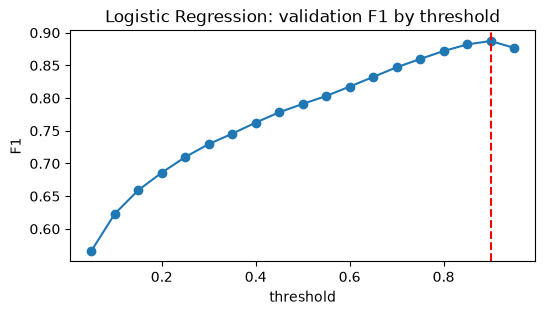

Best model: Logistic Regression | threshold: 0.9


In [10]:
best_name = max(candidates, key=lambda n: results[n]["ROC-AUC"])
best_model = fitted[best_name]
proba_val = best_model.predict_proba(X_val)[:, 1]
thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1s = [f1_score(y_val, (proba_val >= t).astype(int)) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(f1s))])
plt.figure(figsize=(6, 3))
plt.plot(thresholds, f1s, marker="o")
plt.axvline(best_threshold, color="r", ls="--")
plt.title(f"{best_name}: validation F1 by threshold")
plt.xlabel("threshold")
plt.ylabel("F1")
plt.show()
print("Best model:", best_name, "| threshold:", best_threshold)

## Step 9 — Test once

The chosen model and threshold on the unseen last 2 weeks, with the confusion matrix.

TEST: {'accuracy': 0.959, 'precision': 0.937, 'recall': 0.866, 'F1': 0.9, 'ROC-AUC': 0.988}


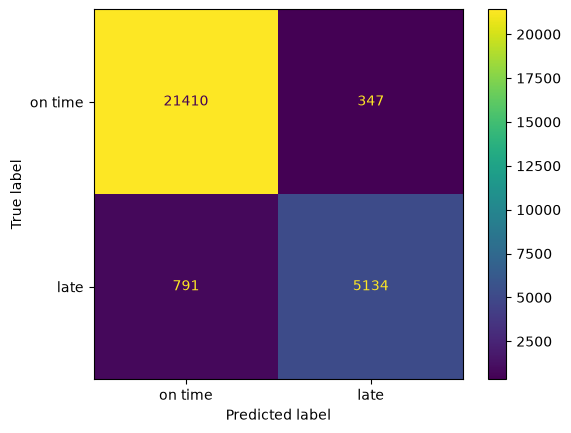

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

proba_test = best_model.predict_proba(X_test)[:, 1]
test_scores = scores(y_test, proba_test, best_threshold)
print("TEST:", {k: round(v, 3) for k, v in test_scores.items()})
ConfusionMatrixDisplay.from_predictions(
    y_test, (proba_test >= best_threshold).astype(int), display_labels=["on time", "late"]
)
plt.show()

## Step 10 — Save & report

Save the pipeline together with its threshold, and the scores.

In [12]:
joblib.dump({"pipeline": best_model, "threshold": best_threshold}, MODELS / "late_risk_v1.joblib")
report = {
    "model": "late_risk_v1",
    "algorithm": best_name,
    "threshold": best_threshold,
    "features": NUMERIC + CATEGORICAL,
    "dataset_version": "v3",
    "validation": {n: {k: round(v, 3) for k, v in s.items()} for n, s in results.items()},
    "test": {k: round(v, 3) for k, v in test_scores.items()},
    "late_share_test": round(float(y_test.mean()), 3),
}
(MODELS / "late_risk_v1_report.json").write_text(json.dumps(report, indent=2))
print("Saved models/late_risk_v1.joblib")
pd.DataFrame(results).T.round(3)

Saved models/late_risk_v1.joblib


,accuracy,precision,recall,F1,ROC-AUC
Baseline (always on time),0.805,0.000,0.000,0.000,0.500
Logistic Regression,0.899,0.664,0.977,0.791,0.988
Random Forest,0.942,0.815,0.910,0.860,0.985
Gradient Boosting,0.912,0.699,0.967,0.811,0.987
XGBoost,0.924,0.737,0.952,0.831,0.986


## Summary

**What we predict:** whether an order will be delivered **late**, at the moment it is assigned
(binary classification).

**Before (without this model):** a late order was only discovered after it was already late. The
baseline "always on time" is 79 % accurate on the test weeks but catches **0 %** of late
orders — accuracy is the wrong measure here.

**Models compared on validation** (threshold 0.5):

| Model | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Baseline (always on time) | 0.00 | 0.00 | 0.00 | 0.500 |
| Logistic Regression | 0.66 | 0.98 | 0.79 | 0.988 |
| Random Forest | 0.81 | 0.91 | 0.86 | 0.985 |
| Gradient Boosting | 0.70 | 0.97 | 0.81 | 0.987 |
| XGBoost | 0.74 | 0.95 | 0.83 | 0.986 |

**Final model:** Logistic Regression (best validation ROC-AUC), decision threshold **0.9**
chosen on validation by scanning 0.05–0.95 for the best F1.

| Test set (last 2 weeks) | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Baseline: always on time | 0.00 | 0.00 | 0.00 | 0.50 |
| **Logistic Regression (late_risk_v1)** | **0.94** | **0.87** | **0.90** | **0.988** |

**What it shows**
- The model catches about **87 %** of late orders and is right about **94 %** of the time it warns.
- Strongest signals: how long the order already queued, its priority (HIGH has the tightest deadline)
  and the hour (rush hours). Much of the risk is visible at assignment because the order has queued;
  a harder next version would predict at the moment the order is **created**.

**How it is used:** risky orders are flagged live (dashboard, Orders page), an alert is written to the
`alerts` table, and each prediction is saved with the real outcome.

**Saved:** `models/late_risk_v1.joblib` (pipeline + threshold), `models/late_risk_v1_report.json`.